# Manuscript figures

Three compact scientific figures from the existing primary analysis. This notebook does not run collection, alter results, or write published figures. Rendering requires the old seal status `COMPLETE_PRIMARY_ANALYSIS_WITH_CAVEATS`, validates consumed CSV artifact hashes, and checks frozen sources and original primary data through `core.load_inputs`.

Figures cover all 24 primary contrasts, iterative US-Hindi sensitivity, and descriptive fixed-model means. Full methods, counts, and limitations are displayed separately from the artwork. These are not equivalence, realism, national-population, or quality-ranking claims.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import sys
from IPython.display import Image, Markdown, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'analysis_figures/manuscript.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Start within the project checkout.')
sys.path.insert(0, str(ROOT))
from analysis_figures.manuscript import render_manuscript

# Keep the workspace alive until this kernel session ends.
manuscript_workspace = TemporaryDirectory(prefix='manuscript-figures-')
TEMP_OUTPUT = Path(manuscript_workspace.name)
figure_paths = render_manuscript(ROOT, TEMP_OUTPUT)
print('Validated sealed evidence; rendered', len(figure_paths), 'temporary PNG/SVG/PDF files.')
print('Old evidence and outputs/manuscript_figures/20261105_v1 were not modified.')

Validated sealed evidence; rendered 9 temporary PNG/SVG/PDF files.
Old evidence and outputs/manuscript_figures/20261105_v1 were not modified.


# Manuscript Figure Captions

These figures use only the original primary cohort: 896 scheduled attempts,
890 valid graphs, six terminal failures, and 12 valid empty graphs. Analyses
are conditional on one fictional 50-adult roster, four fixed model
configurations, seven named instruction conditions, and eight schedule seeds.
US-English is the paired baseline. A seed is a schedule block, not an
independent model or human population. Failed and undefined endpoints remain
missing. No figure establishes equivalence, representative national or
language effects, empirical realism, or an overall model ranking.


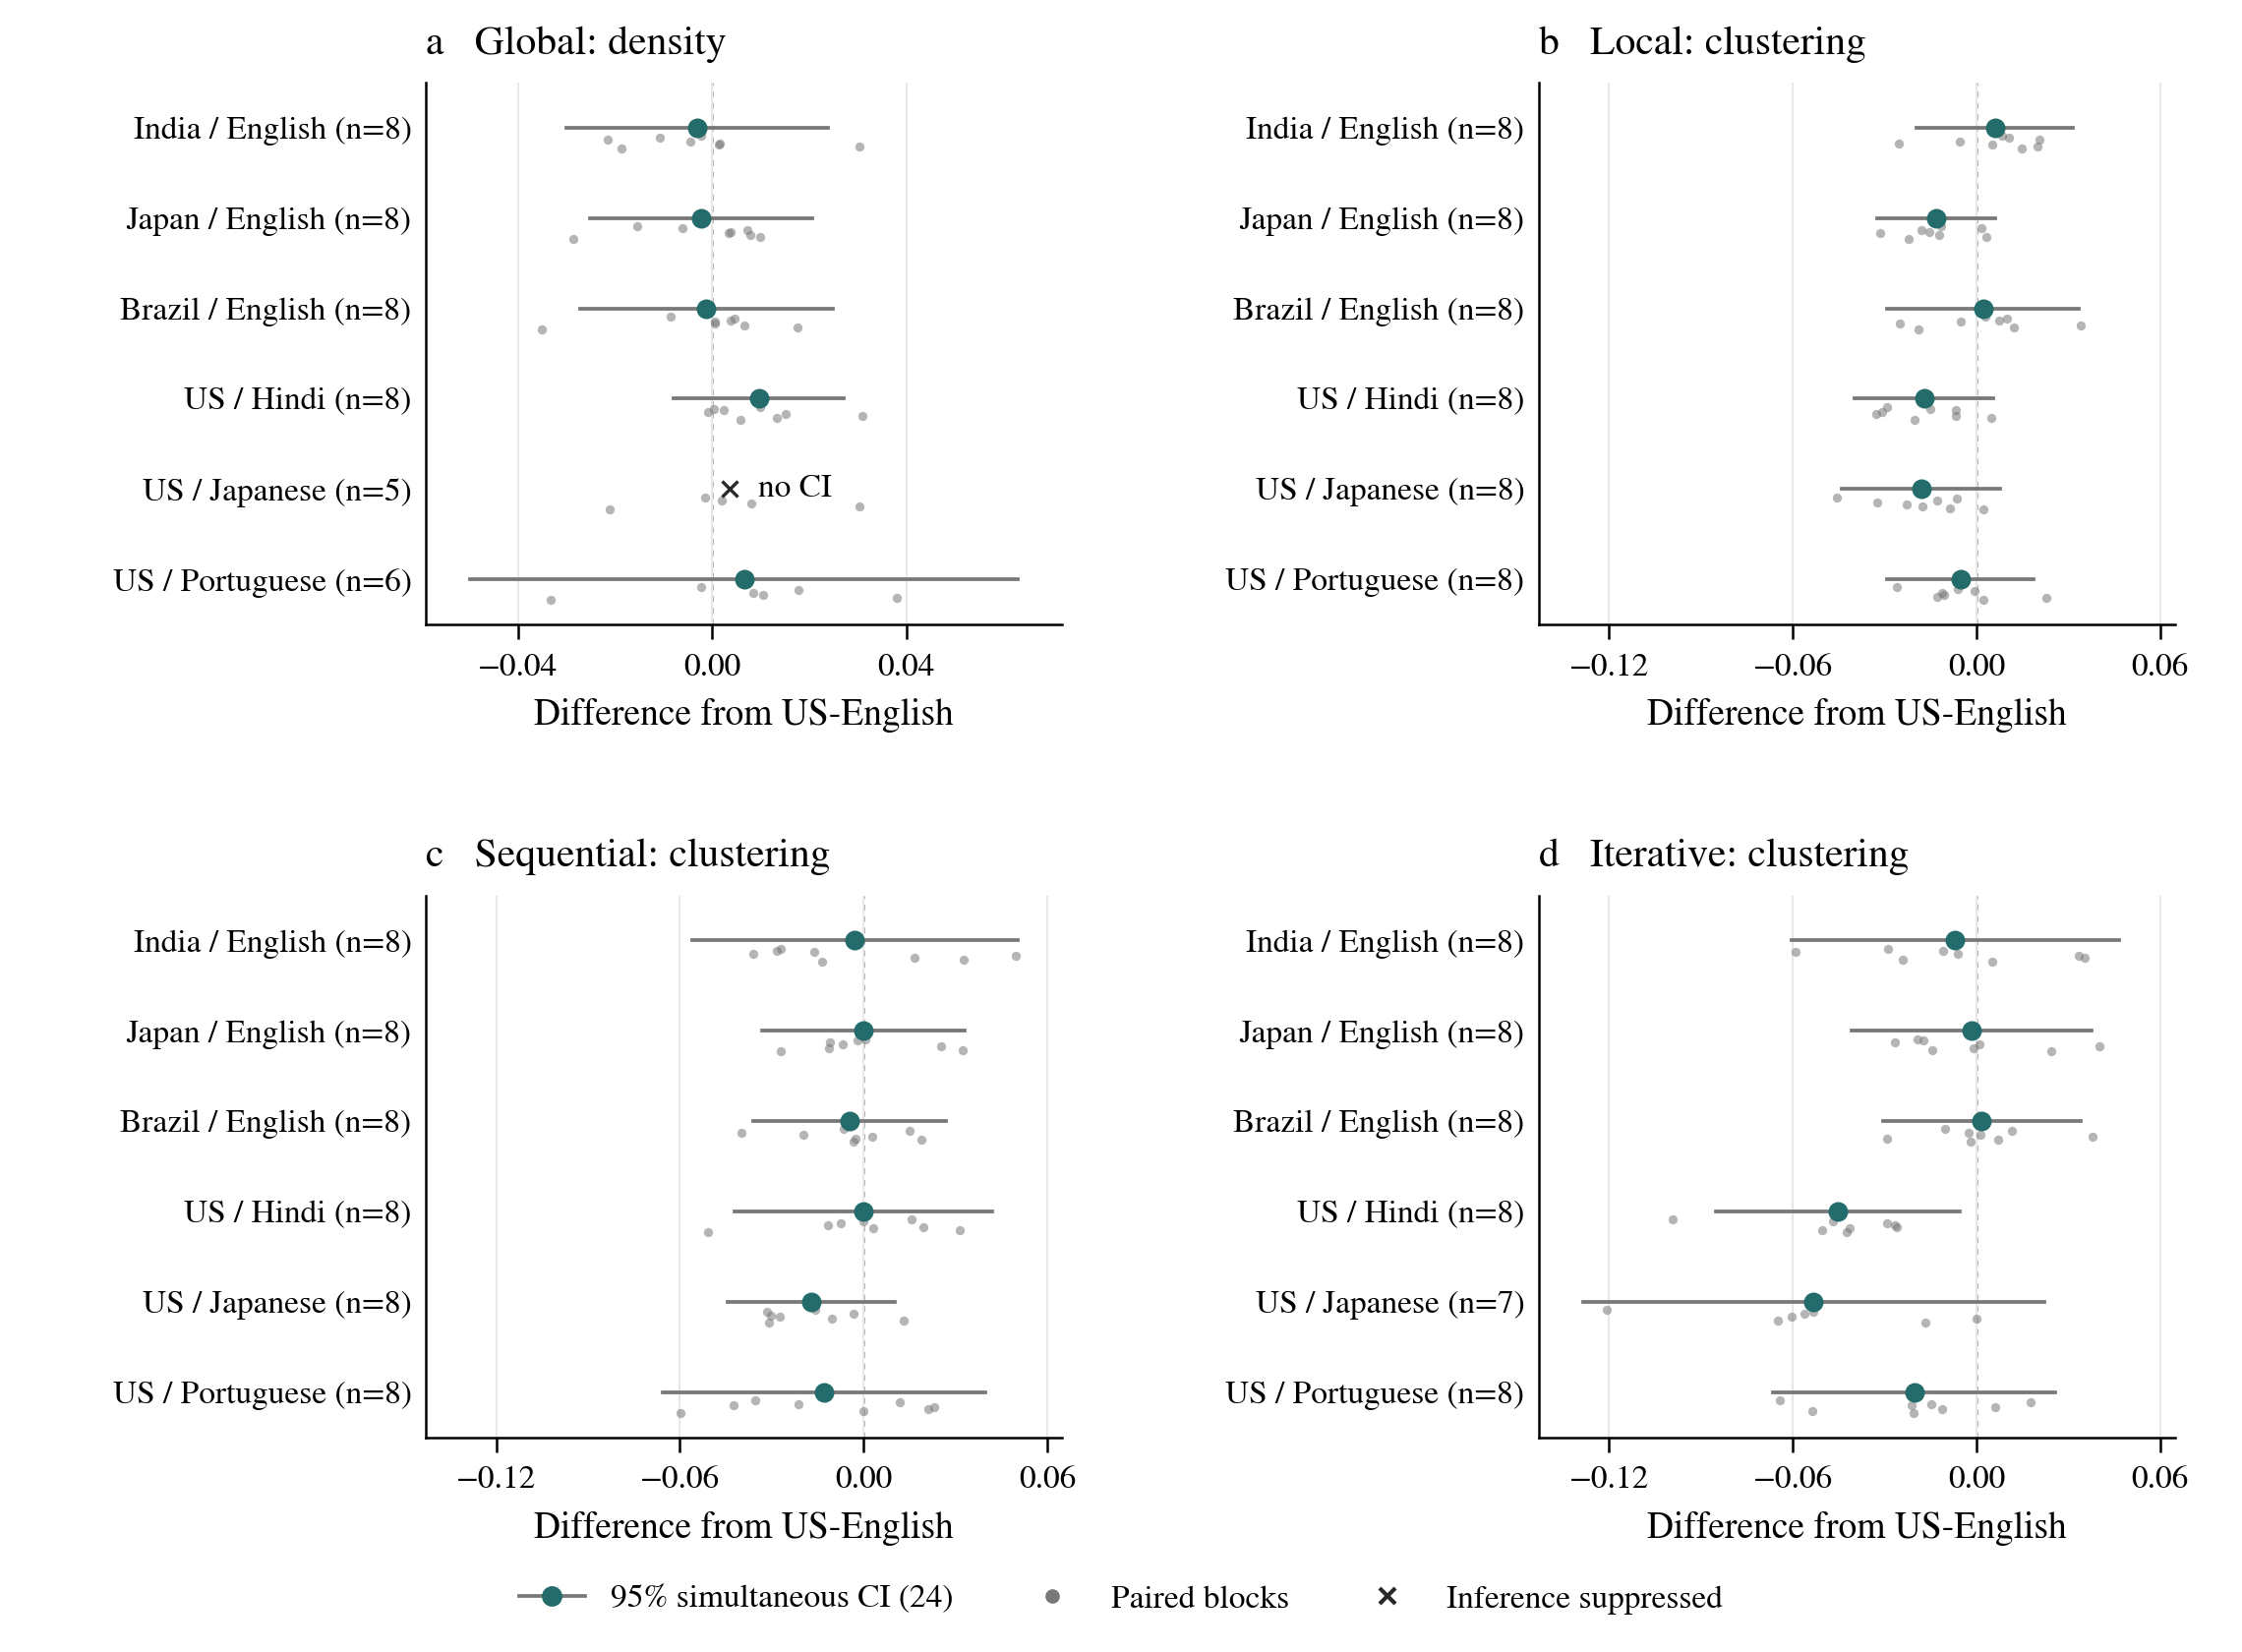

## Figure 1. Primary Contrasts

**Method.** All 24 planned primary contrasts are shown in their original
method/condition order. Each large point is the mean complete-block difference
from same-seed US-English, with each block averaging the four fixed models.
Small gray dots below each estimate show the individual complete paired
block differences, with deterministic vertical separation by seed order;
horizontal values are not jittered. Dashed zero lines mark no difference.
Global uses density; local, sequential, and iterative use mean clustering
coefficient. Horizontal segments are the archived 95% family-simultaneous
Bonferroni t intervals across 24 hypotheses, not pointwise 95% intervals.
The full 24-hypothesis Holm family is retained. Tick-label n is the number
of complete blocks out of eight. The three clustering panels share one
x-axis range; the density panel has its own endpoint-specific range. Axis
ranges include all displayed block values as well as all intervals.

**Limits.** Global US-Japanese has only five complete blocks: its cross is
a descriptive mean, without a confidence interval or primary test. Global
US-Portuguese has six complete blocks and iterative US-Japanese seven;
the other 21 contrasts have eight. Inference requires independent blocks
and adequate t approximations; complete-block analyses additionally require
ignorable missingness. Identification bounds for missing endpoints are not
confidence intervals and are not shown here. Holm decisions and Bonferroni
interval exclusion need not coincide. Nonsignificance does not establish
sameness or a small effect.


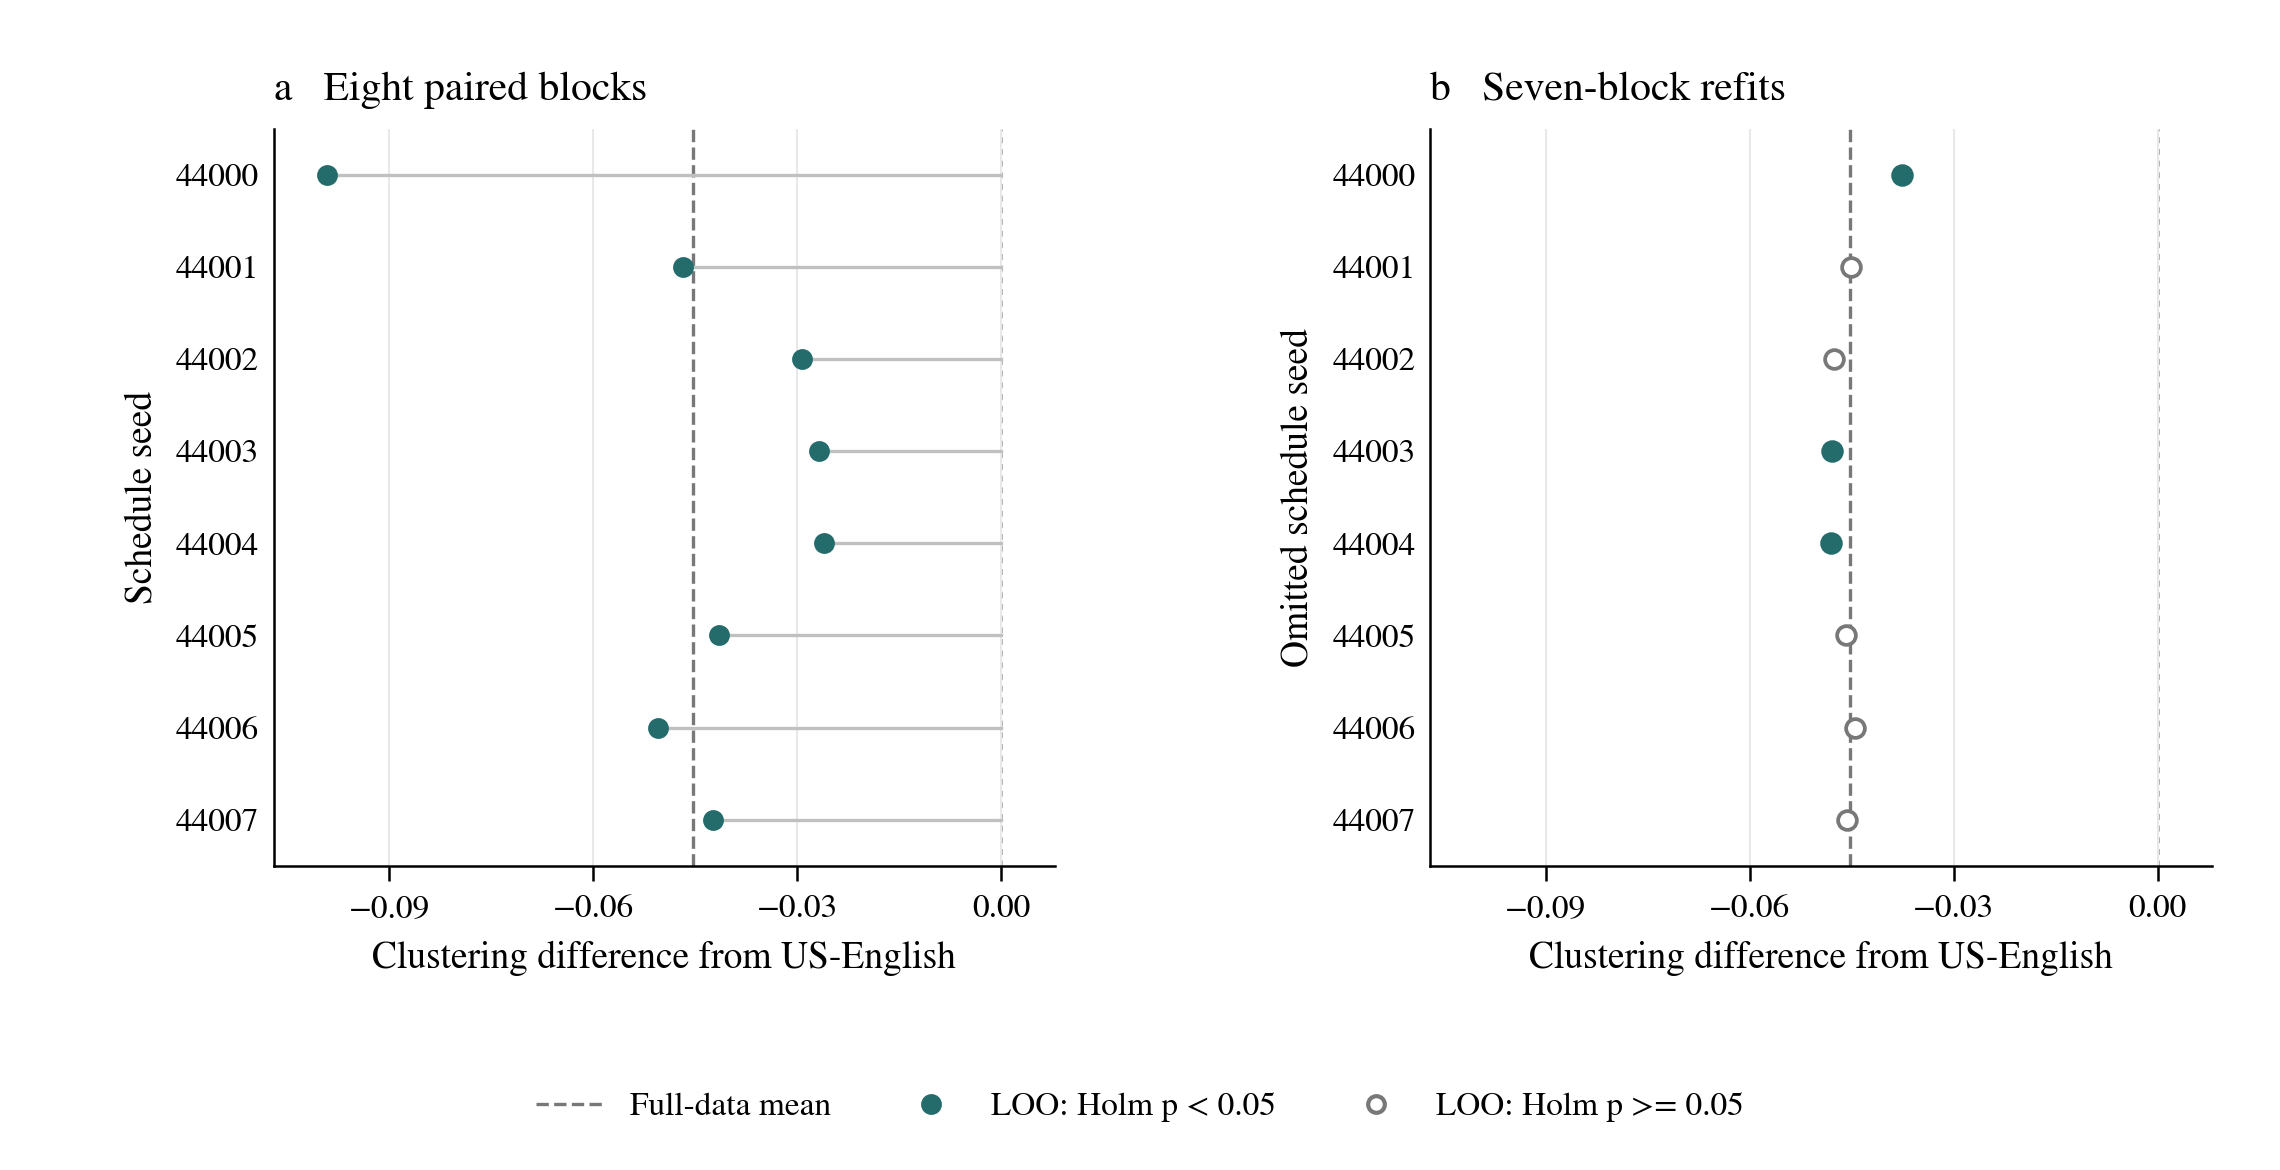

## Figure 2. Iterative US-Hindi Sensitivity

**Method.** Panel a shows the eight complete schedule-block clustering
differences for iterative US-Hindi versus same-seed US-English. Panel b
shows eight leave-one-schedule-out means, each retaining seven blocks;
the y-axis identifies the omitted seed. Both panels share an x-axis range.
The darker dashed vertical line is the full-data mean difference, -0.045279;
the light short-dashed reference is zero.
Filled panel-b markers denote refits with Holm p < 0.05; open markers denote
the remaining refits. Holm adjustment is repeated over the complete
24-hypothesis family within each refit. Only 3/8 refits meet that threshold.
The full-data primary t diagnostic has Holm p = 0.023831.

**Limits.** All eight observed block differences are negative, but inference
is sensitive to which schedule is omitted. The refits overlap heavily and
are not eight independent replications; 3/8 is a diagnostic count, not a
probability of replication. The plotted refit means have no confidence
intervals. These post-collection sensitivity displays were selected for
the primary finding and do not form a new confirmatory family. The separate
exploratory exact sign-flip diagnostic has full-family Holm p = 0.1875;
it relies on sign symmetry, not causal randomization. The figure does not
establish robustness, equivalence, or a population effect.


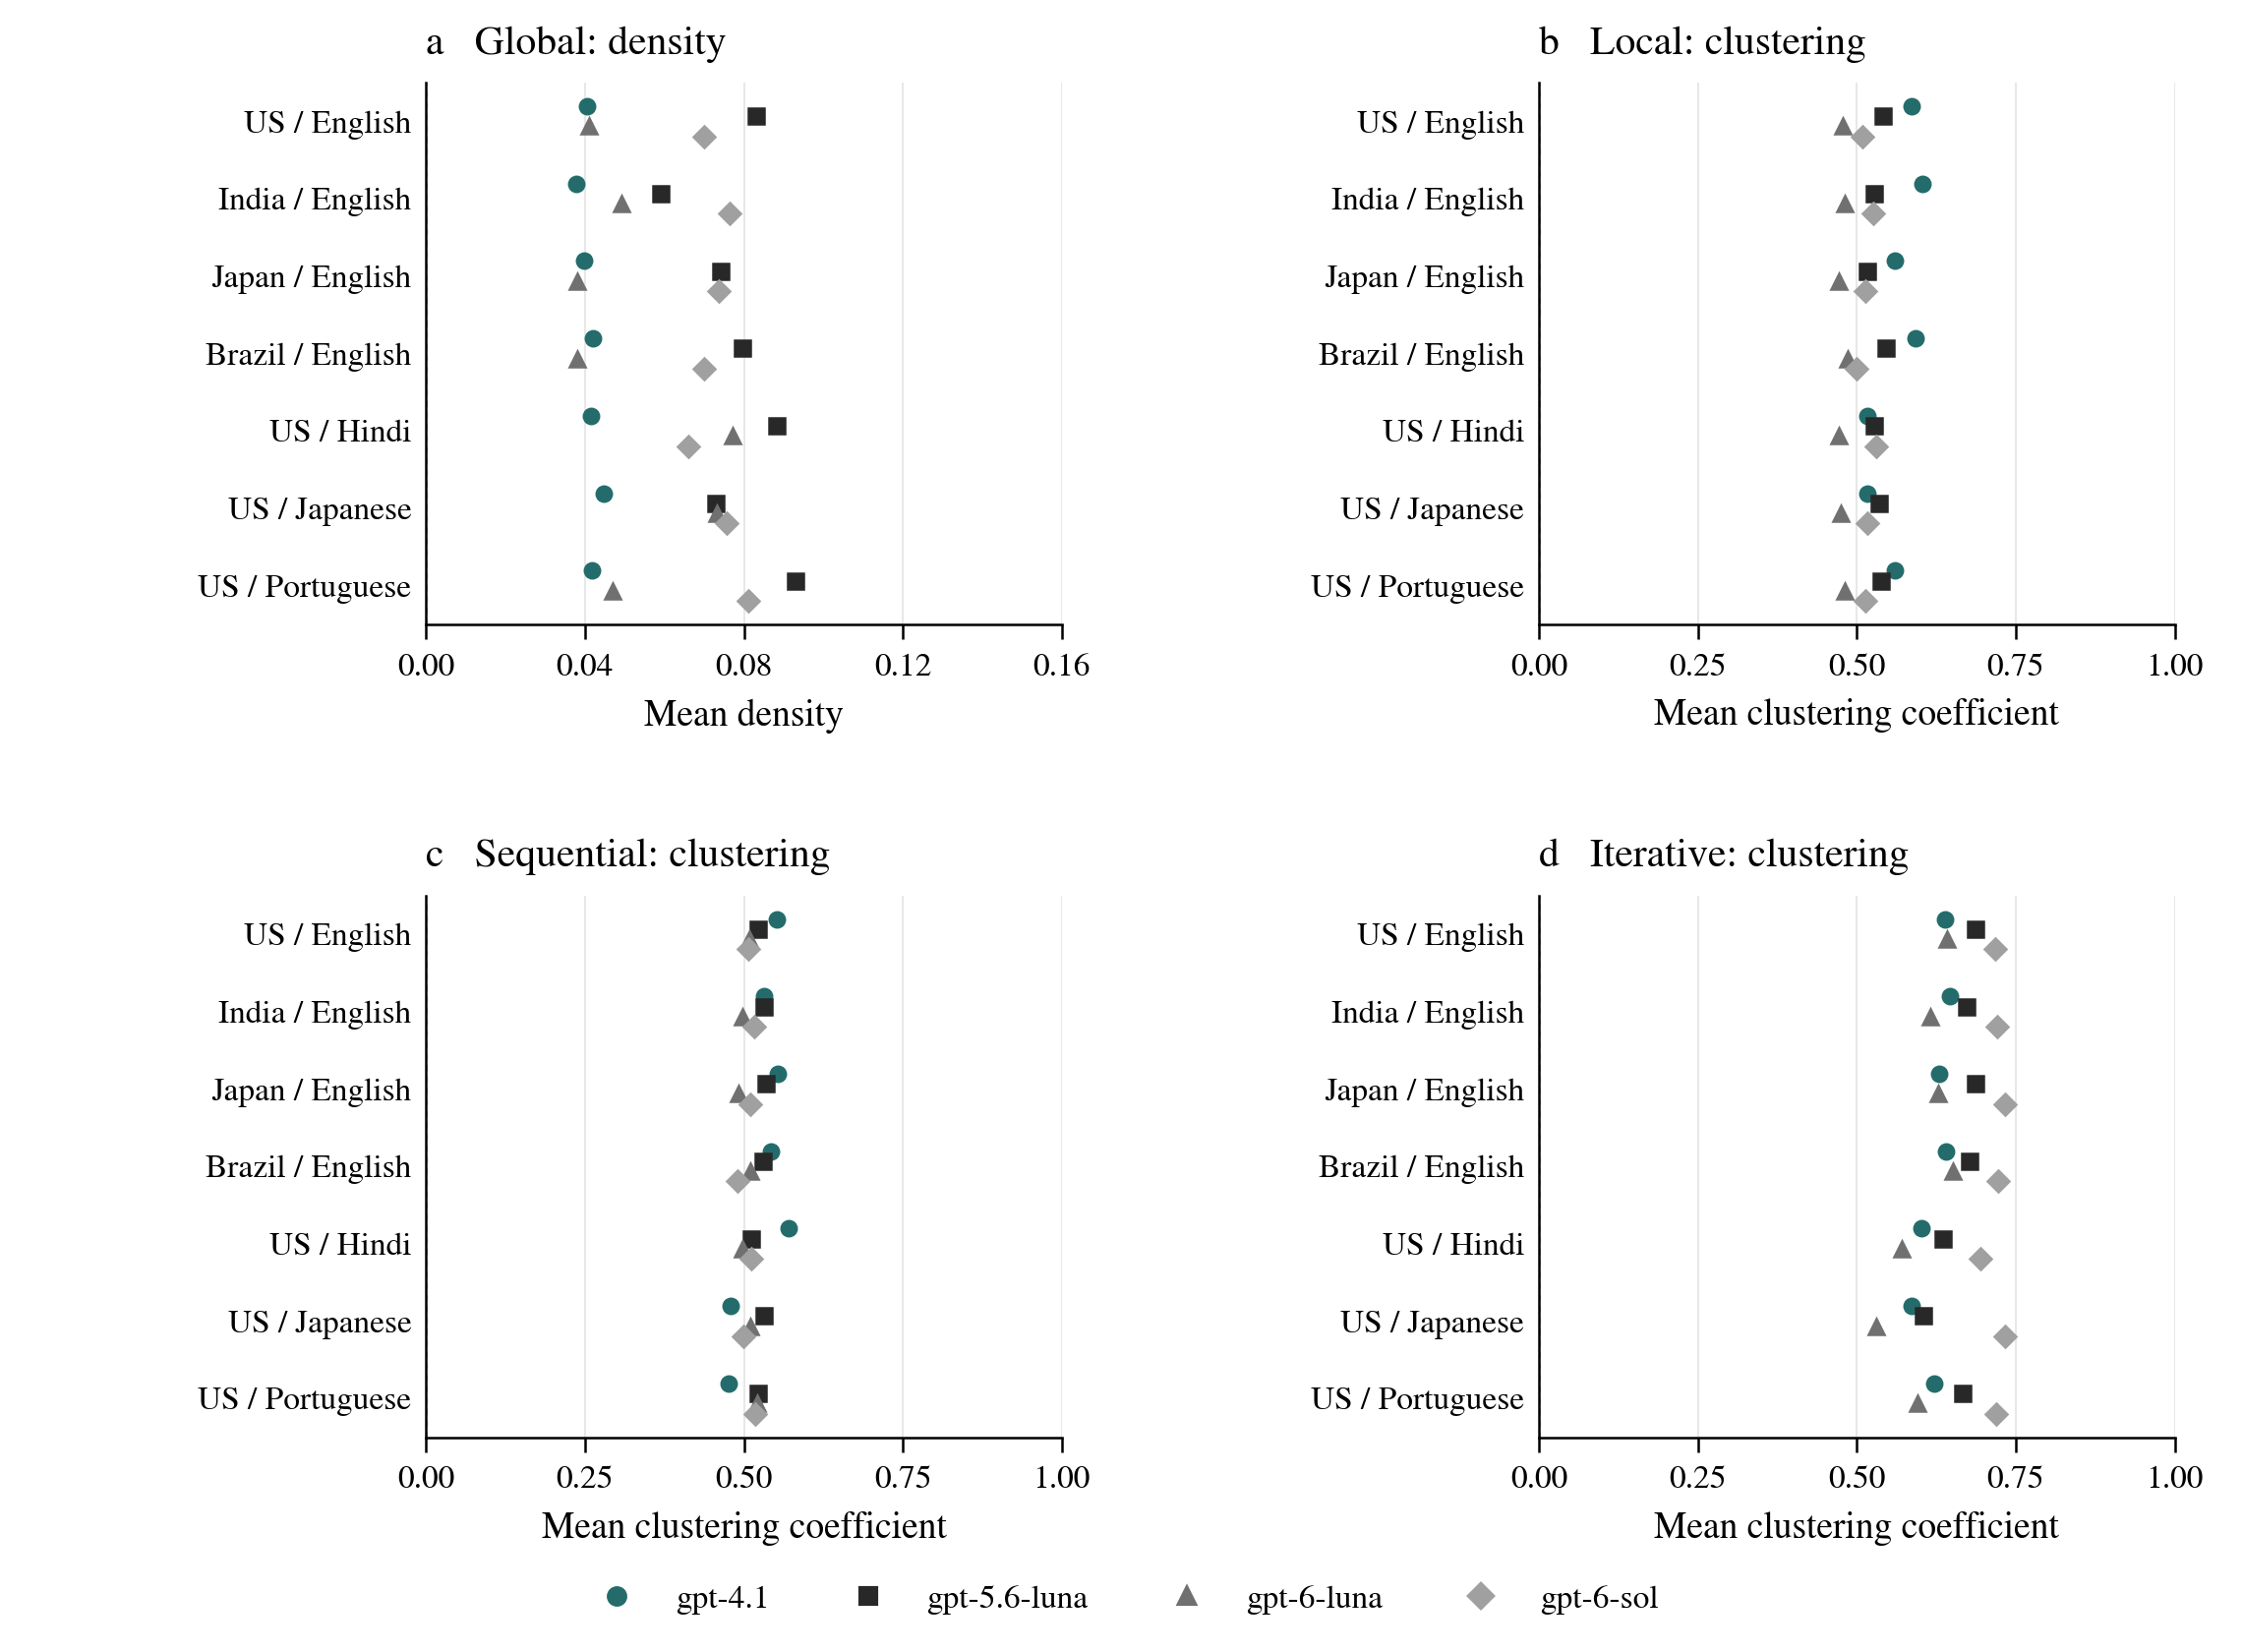

## Figure 3. Descriptive Fixed-Model Endpoint Means

**Method.** Four method panels show arithmetic endpoint means for all four
fixed model configurations and all seven instruction conditions. Models
use consistent shapes and shades, with a single shared legend. Global
shows density; the other panels show mean clustering coefficient on a
common 0-1 scale. Both endpoint scales include zero. These are descriptive
means, without inferential error bars. Each model/method/condition cell has
eight scheduled attempts; only valid, defined endpoints enter its mean.
Exact counts are stored in the hash-sealed `descriptive_metrics.csv`,
column `endpoint_defined`. The following are the only counts below eight:

| Method | Model | Condition | Defined / attempted |
| --- | --- | --- | --- |
| Global | gpt-5.6-luna | US-Japanese | 7/8 |
| Global | gpt-6-luna | US-Japanese | 7/8 |
| Global | gpt-6-sol | US-Japanese | 7/8 |
| Global | gpt-5.6-luna | US-Portuguese | 6/8 |
| Iterative | gpt-4.1 | US-Japanese | 7/8 |

**Limits.** Density and clustering are distinct structural endpoints, not
interchangeable quality scores. The models are four named configurations,
not a random sample of model families. Means do not establish equality,
an instruction's fidelity, realism, or a model ranking. Missing graphs are
not replaced by zero; valid empty graphs retain their defined zero metrics.


## Provenance

Source: `outputs/primary_analysis/20261105/`. Rendering requires the exact
manifest status `COMPLETE_PRIMARY_ANALYSIS_WITH_CAVEATS`, verifies consumed
CSV bytes against its `artifacts` hashes, and invokes `core.load_inputs`
to validate frozen sources and original primary input provenance. Numeric
results and the old artifacts are not recomputed or overwritten. The
renderer also checks the selected leave-one-out means against their
retained block differences. Canonical publication destination:
`outputs/manuscript_figures/20261105_v1/`. Notebook04 instead renders to
a temporary workspace and keeps that workspace alive through display.


Vector SVG and PDF copies remain in C:\Users\Hemu\AppData\Local\Temp\manuscript-figures-6yqsny4b


In [2]:
captions = (ROOT / 'docs/MANUSCRIPT_FIGURE_CAPTIONS.md').read_text(encoding='utf8')
sections = captions.split('\n## Figure ')
display(Markdown(sections[0]))
pngs = [path for path in figure_paths if path.suffix == '.png']
for index, path in enumerate(pngs, 1):
    display(Image(filename=str(path)))
    display(Markdown('## Figure ' + sections[index].split('\n## Provenance')[0]))
display(Markdown('## Provenance' + captions.split('\n## Provenance', 1)[1]))
print('Vector SVG and PDF copies remain in', TEMP_OUTPUT)